# Dimensionality reduction

## PCA

Principal component analysis (PCA) is an unsupervised method that applies a coordinate transformation to the data so that the new coordinate axes are ordered by how much variance the data show along them.
A very common application is to project onto the first (few) coordinates after a PCA, reducing the number of dimensions without throwing away too much of the information in the data.

When somebody says "we do a PCA", they usually mean steps 1–2, often also 1–3:

1. **fit** – compute from the data a linear, invertible coordinate transformation – more precisely, an orthonormal basis. The new coordinate axes are called **principal components** or **principal axes**, and they are ordered by how much variance the data show along them.
2. **transform** – apply the transformation to data. These may well be data other than the ones it was computed from; that is exactly why there are two steps.
3. **dimensionality reduction** – project the transformed data onto the first principal components, that is, onto a low-dimensional linear subspace.

In Scikit-Learn the first two steps are called exactly that (`PCA().fit(x)`, `pca.transform(x)`, and `fit_transform` for both at once), and step 3 lives in the parameter `n_components`: `PCA(n_components=2)` throws away all but the first two principal components when transforming. Leave `n_components` out and you get nothing but a rotation of the coordinate system – and lose nothing.

```{admonition} Example
If you have data in three-dimensional space whose third coordinate $z$ is always $1$, then projecting onto the $xy$ plane changes nothing about the information content of the data. If, on the other hand, the data vary slightly around $1$ in the $z$ coordinate but considerably more in the $x$ and $y$ coordinates, then projecting onto the $xy$ plane changes the information content only a little.
```

The two figures show exactly these two cases: in blue the original data in space, in grey their projections onto the coordinate planes, and as an overlay the difference in total variance before and after the projection onto the $xy$ plane.

```{figure} images/case_a_dual_proj.png
:width: 600px
:align: center
:name: pca-case-a

Case (a): $z$ is constantly $1$. The projection onto the $xy$ plane has exactly the same total variance as the original data – the third coordinate carries no information.
```

```{figure} images/case_b_dual_proj.png
:width: 600px
:align: center
:name: pca-case-b

Case (b): $z \sim \mathcal{N}(1,\ 0.1^2)$. Now something is lost in the projection, but only $0.01$ out of a total variance of $2.28$ – less than half a per cent.
```

Case (b) is the realistic one: a coordinate is never exactly constant, it just varies very little. PCA makes this quantitative – it says not only *that* you may project, but also how much variance it costs (in Scikit-Learn, `pca.explained_variance_ratio_`).

A coordinate transformation is nothing but multiplication by an invertible square matrix. Such a matrix can compress or stretch in any direction, rotate about any axis by an angle, or shear. The goal of PCA is to find coordinates in which the first axis, the $x$ axis, carries the highest variance.
Recall: if a matrix is read as a linear map by matrix multiplication, the images of the basis vectors are exactly the columns of the matrix.
If we can find a vector pointing in the direction of greatest variance, we can write it into a matrix as the first column and project onto the subspace orthogonal to it (that is, we consider all vectors at a right angle to our first matrix column, which leaves a vector space one dimension smaller).
Carrying on inductively, we obtain a matrix $M$. The inverse map $M^{-1}$ is then a transformation that maps the direction of greatest variance onto the first standard basis vector, that is, onto the $x$ axis.

Because we normalise every principal axis and always look for the next one in the orthogonal complement of the previous ones, the columns of $M$ are normalised and pairwise perpendicular: they form an orthonormal basis. Such a matrix is called **orthogonal** (also: orthonormal matrix). It satisfies $M^\top M = I$ (identity matrix), hence $M^{-1} = M^\top$: the back-transformation is simply the transpose, and the inversion comes for free. Why the principal axes come out perpendicular to each other of their own accord is something we shall see at the end of the derivation below.

Unfortunately we have not yet said how to find the direction of greatest variance.

### Derivation

```{admonition} Example
If we look at a sample from a bivariate standard normal distribution, we can draw a circle around the 95\% quantile.
The matrix $\begin{pmatrix} 2 & 0 \\ 0 & 1\end{pmatrix}$ is a stretching along the $x$ axis, and it turns the pretty circle into an elongated ellipse.
The direction of greatest variance is then exactly the $x$ axis.
```

```{admonition} Example
If an arbitrary invertible matrix $M = \begin{pmatrix} a & b \\ c & d \end{pmatrix}$ is applied to a sample from a bivariate standard normal distribution, the directions of greatest variance are the directions that $M$ stretches most. For symmetric $M$ this is a vector $v$ with $Mv = \lambda v$ for the largest such $\lambda$ (for arbitrary $M$ it would be the direction of the largest singular value; we shall see in a moment that the symmetric case is all we need).
```

These examples suggest asking which matrix $M$ could have produced the observed data from a standard normal distribution (or at least, for which matrix that would be most plausible). The eigenvectors belonging to the largest eigenvalue of $M$ are precisely the directions of greatest variance.

```{admonition} Example
If we look at the covariance matrix of a bivariate standard normal distribution, that is, $\begin{pmatrix} \mathbb{V}(X) & Cov(X,Y) \\ Cov(Y,X) & \mathbb{V}(Y) \end{pmatrix} = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}$,
and then at how the covariance matrix of a sample changes when we carry out the coordinate transformation $\begin{pmatrix} 2 & 0 \\ 0 & 1\end{pmatrix}$,
we observe a squaring: in the sample covariance $Cov(x,y) = \frac{1}{n} \sum_{i=1}^n x_iy_i$ the scaling by $2$ enters only once, but in $\mathbb{V}(x) = Cov(x,x)$ it enters squared. The effect of the coordinate transformation is therefore the "square root" of the covariance matrix after the transformation (mind you, only because we had arranged for the covariance matrix beforehand to be the identity map, that is, the identity matrix).
```

Such a covariance matrix can always be set up. If we do that with our real data and could then take a "square root" of it, we would have found the matrix $M$.
Fortunately, covariance matrices have a special property: they are positive definite and symmetric. (In the chapter [The multivariate normal distribution](multivariate-normal.ipynb) we saw that the covariance matrix describes the ellipses of the density; the eigenvectors we are now computing are exactly the axes of those ellipses.)

```{admonition} Definition
A square matrix $C$ is called **symmetric** if $C = C^\top$. A symmetric matrix $C$ is called **positive definite** if $v^\top C v > 0$ for all vectors $v \neq 0$. For symmetric matrices this is equivalent to all eigenvalues of $C$ being positive. If only $v^\top C v \geq 0$ holds for all $v$ (equivalently: all eigenvalues are $\geq 0$), then $C$ is called **positive semidefinite**.
```

```{admonition} Remark
If $D$ is the centred data matrix (one row per data point, every column with mean $0$), then the empirical covariance matrix is $C = \frac{1}{n} D^\top D$. It is obviously symmetric, and for every vector $v$ we have

$$v^\top C v = \frac{1}{n} v^\top D^\top D v = \frac{1}{n} \|Dv\|^2 \geq 0.$$

Here $Dv$ is the vector of the coordinates of all data points in the direction $v$; so for a unit vector $v$, $v^\top C v$ is the variance of the data in the direction $v$. Hence $C$ is always positive semidefinite, and positive definite exactly when $Dv = 0$ forces $v = 0$, that is, when the columns of $D$ are linearly independent. With real data that is practically always the case (the eigenvalue $0$ occurs only when the data do not spread out at all in some direction), which is why we work with "positive definite" in what follows.
```

```{admonition} Theorem
For every positive definite symmetric matrix $C$ there exists an invertible matrix $\Sigma$ with $\Sigma^2 = C$.
```

There is a very simple way to find this matrix $\Sigma$ if $C$ is a diagonal matrix with nothing but positive entries: then $\Sigma$ is the diagonal matrix of the respective square roots.
If $C$ is not a diagonal matrix, there are procedures for changing coordinates so as to turn $C$ into one. Mathematically this means that $C$ can be replaced by a transformation $T$ backwards, then a diagonal matrix $C'$, then the transformation $T$ forwards. In formulas: $C = T C' T^{-1}$.

Suppose we have found such a decomposition (also called an eigenspace decomposition). Then we can compute $\Sigma'$ as a square root of $C'$, and $\Sigma = T \Sigma' T^{-1}$ satisfies

$$\Sigma^2 = T \Sigma' T^{-1} T \Sigma' T^{-1} = T \Sigma'^2 T^{-1} = T C' T^{-1} = C.$$

The matrix $T$ we are after satisfies $C = T C' T^{-1}$, or, rearranged, $C T = T C'$. For every column $v = T_{,i}$ of $T$ and the $i$-th diagonal entry $\alpha_i$ of $C'$ this gives an equation $C v = v \alpha_i$: the columns of $T$ are exactly the eigenvectors of $C$, and the diagonal entries of $C'$ are exactly the eigenvalues of $C$ belonging to them.

```{admonition} Theorem
For every symmetric matrix $C$ there is an orthonormal basis of eigenvectors of $C$ (spectral theorem, without proof). If these eigenvectors are written as the columns of a matrix $T$, then $T^\top T = I$ and therefore $T^{-1} = T^\top$.
```

That eigenvectors belonging to different eigenvalues are perpendicular can be checked in one line: if $C v_1 = \lambda_1 v_1$ and $C v_2 = \lambda_2 v_2$ with $\lambda_1 \neq \lambda_2$, then, because $C = C^\top$,

$$\lambda_1 v_1^\top v_2 = (C v_1)^\top v_2 = v_1^\top C v_2 = \lambda_2 v_1^\top v_2,$$

hence $(\lambda_1 - \lambda_2)\, v_1^\top v_2 = 0$ and therefore $v_1^\top v_2 = 0$. If the eigenvectors are normalised as well, then $T^\top T$ is the matrix of all inner products $v_i^\top v_j$, that is, the identity matrix. This is why the "rotation" of PCA (the matrix $M$ from the section on coordinate transformations above) is inverted by mere transposition, $T^{-1} = T^\top$ – which the code below exploits too.

```{admonition} Remark
Let us summarise the derivation. We imagined the data $X$ arising from a standard normal distribution $Y$ by a coordinate transformation, $X = \Sigma Y$; the empirical covariance matrix then estimates $C = \Sigma^2$ (since $\Sigma = \Sigma^\top$, we have $\Sigma \Sigma^\top = \Sigma^2$). The direction of greatest variance is an eigenvector $v$ belonging to the largest eigenvalue $\lambda$ of $\Sigma$. But the square root $\Sigma$ never needs to be computed for that, because

$$\Sigma v = \lambda v \quad \Rightarrow \quad C v = \Sigma^2 v = \Sigma (\lambda v) = \lambda^2 v,$$

that is, $v$ is also an eigenvector of $C$, belonging to the eigenvalue $\lambda^2$. So the eigenvectors of $\Sigma$ and $C$ coincide; only the eigenvalues get squared (that is exactly the "squaring" from the example above), and their order is preserved.

In the end, the normality assumption is not needed at all. For a unit vector $v$, $v^\top C v$ is the variance of the data in the direction $v$ (see the remark above), and over all unit vectors this expression is maximised precisely by an eigenvector belonging to the largest eigenvalue of $C$, the maximum being that eigenvalue (Rayleigh quotient, see linear algebra; we do not prove it here). The eigenvector belonging to the largest eigenvalue of the empirical covariance matrix is therefore **always** the direction of greatest variance, for data from any distribution with finite variance.
```

So we have all the ingredients, provided only that we can somehow find the eigenvectors of the covariance matrix!

A good procedure for finding the eigenvector belonging to the largest eigenvalue: start with a random vector and apply the matrix to it. If it is an eigenvector – good, we note it down. If not, the matrix maps the vector into a direction that, with higher probability, points a little more towards the eigenvector belonging to the largest eigenvalue. So if we apply the matrix repeatedly, the chances are good that we get closer and closer to an eigenvector.

A less efficient procedure is the one you should have learned in linear algebra: first find the eigenvalues as the roots of the characteristic polynomial $\det(M - X Id)$, then for every eigenvalue $\alpha$ find the eigenspace $Ker(M - \alpha Id)$ by Gaussian elimination, that is, by solving the equation $Mv = \alpha v$.

Numpy and Scikit-Learn fall back on LAPACK, which is written in Fortran and carries out a singular value decomposition (the decomposition $C = TC' T^{-1}$) in two steps. We shall not rack our brains over this any further; it belongs in a linear algebra or numerical analysis course.
We do, of course, still want the computer's help:

In [1]:
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
from sklearn import datasets

In [2]:
C = np.array([[2.5, 0.5], [0.5, 1.75]])       # for example!
# C is symmetric, so we take eigh: real eigenvalues, guaranteed sorted in ascending order
# (np.linalg.eig guarantees no particular order of the eigenvalues).
eigenvalues, eigenvectors = np.linalg.eigh(C)
eigenvalues, eigenvectors = eigenvalues[::-1], eigenvectors[:, ::-1]   # descending, as in the SVD
print(eigenvalues)
print(eigenvectors)
T, s, vh = np.linalg.svd(C) # SVD = Singular Value Decomposition; singular values descending
assert np.allclose(s, eigenvalues)
print("in this example the transformation T is:")
print(T)
# Since C is symmetric positive definite, T is orthogonal, so vh = T^{-1} = T^T
# (eigenvectors are unique only up to sign, which is why eigenvectors and T
#  may differ in the signs of individual columns.)
assert np.allclose(vh, T.T)

[2.75 1.5 ]
[[-0.89442719  0.4472136 ]
 [-0.4472136  -0.89442719]]
in this example the transformation T is:
[[-0.89442719 -0.4472136 ]
 [-0.4472136   0.89442719]]


The eigenvalues are the variances of the data along the corresponding eigenvectors, the *principal components*. Their share of the total variance $\operatorname{tr}(C) = 2.5 + 1.75 = 4.25$ – here $2.75/4.25 \approx 65\%$ and $1.5/4.25 \approx 35\%$ – is called the *explained variance* of the respective component. This is the quantity you later use to decide how many components to keep.

### Dimensionality reduction in five steps

From a dataset $x_1, \dots, x_N \in \mathbb{R}^d$, PCA makes a dataset in $\mathbb{R}^k$ with $k < d$:

1. **Centring:** subtract its mean from every feature, so that the dataset has its centre of mass at $0$
   (usually with scaling as well, see below).
2. Compute the **covariance matrix** $C$ of the centred data.
3. **Eigendecomposition:** determine the eigenvalues $\lambda_1 \geq \dots \geq \lambda_d$ and the corresponding
   normalised eigenvectors $v_1, \dots, v_d$ of $C$.
4. **Selecting:** keep the $k$ eigenvectors belonging to the largest eigenvalues – they explain the fraction
   $(\lambda_1 + \dots + \lambda_k) / \operatorname{tr}(C)$ of the total variance.
5. **Projecting:** map every centred data point $x$ to its new coordinates
   $\big(\langle x, v_1 \rangle, \dots, \langle x, v_k \rangle\big)$.

```{admonition} Example
For $C = \begin{pmatrix} 5 & 3 \\ 3 & 5 \end{pmatrix}$ the eigenvalues are $\lambda_1 = 8$ and $\lambda_2 = 2$ with
eigenvectors $v_1 = \frac{1}{\sqrt 2}(1, 1)^\top$ and $v_2 = \frac{1}{\sqrt 2}(1, -1)^\top$; the first principal component
explains $8/10 = 80\,\%$ of the variance. The centred point $x = (2, 2)^\top$ has the new coordinates
$\langle x, v_1 \rangle = \frac{4}{\sqrt 2} = 2\sqrt 2 \approx 2.83$ and $\langle x, v_2 \rangle = 0$.
A point on the diagonal has coordinate $0$ in the direction $v_2$ – it lies exactly on the first
principal axis, and reducing to one dimension loses nothing for it.
```


In [3]:
C = np.array([[5.0, 3.0], [3.0, 5.0]])
values, vectors = np.linalg.eigh(C)
values, vectors = values[::-1], vectors[:, ::-1]        # descending
print("eigenvalues:", values, " explained variance of the 1st PC:", values[0] / values.sum())

x = np.array([2.0, 2.0])
new_coordinates = vectors.T @ x                         # step 5: inner products with v_1, v_2
print("new coordinates:", new_coordinates)
assert np.isclose(abs(new_coordinates[0]), 2 * np.sqrt(2)) and np.isclose(new_coordinates[1], 0)


eigenvalues: [8. 2.]  explained variance of the 1st PC: 0.8
new coordinates: [2.82842712 0.        ]


Now, instead of the made-up covariance matrix $C$, we look at a real sample $x$, distort it with a coordinate transformation, and then 'undo' that transformation with the method just discussed:

[[45.35696351 12.19917054]
 [12.19917054  6.1101751 ]]


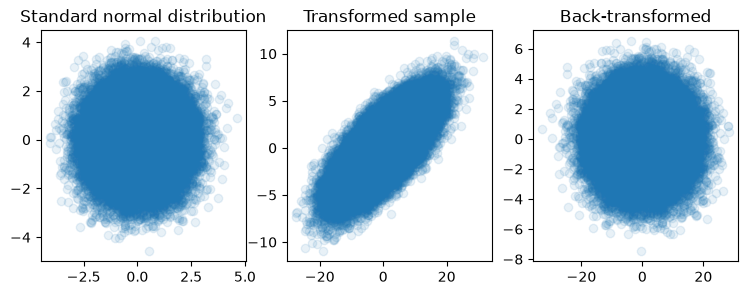

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(9, 3))


x = st.multivariate_normal(mean=[0,0], cov=np.eye(2)).rvs(100000)
C = np.cov(x, rowvar=False)
assert np.all(np.isclose(np.eye(2), C, atol=0.1))
axs[0].scatter(x[:,0], x[:,1], alpha=0.1)
axs[0].set_title("Standard normal distribution")

# an arbitrary transformation:
Q = np.array([[6.75, 0.25], [1.75, 1.75]])
new_x = np.matmul(Q, x.T).T
axs[1].scatter(new_x[:,0], new_x[:,1], alpha=0.1)
axs[1].set_title("Transformed sample")
new_C = np.cov(new_x, rowvar=False)
print(new_C)

T, s, Tinv = np.linalg.svd(new_C)
newer_x = np.matmul(Tinv, new_x.T).T
axs[2].scatter(newer_x[:,0], newer_x[:,1], alpha=0.1)
axs[2].set_title("Back-transformed")

plt.show()

Look at the plots very closely. Have we undone the transformation completely? And either way, how can you tell?

### Computation

In just the same way we can, of course, proceed with data we did not transform ourselves – data that may never have been sampled from a standard normal distribution in the first place.

[[ 0.68569351 -0.042434    1.27431544  0.51627069]
 [-0.042434    0.18997942 -0.32965638 -0.12163937]
 [ 1.27431544 -0.32965638  3.11627785  1.2956094 ]
 [ 0.51627069 -0.12163937  1.2956094   0.58100626]]


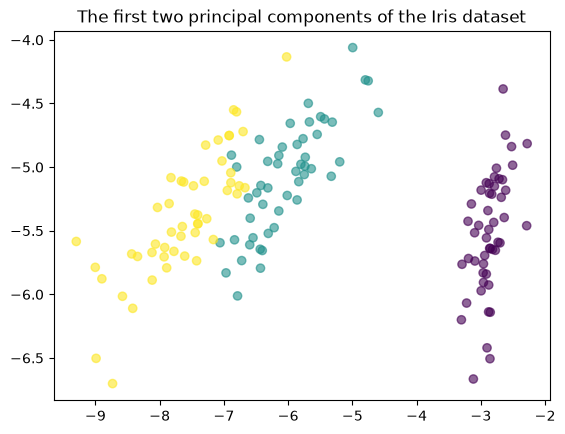

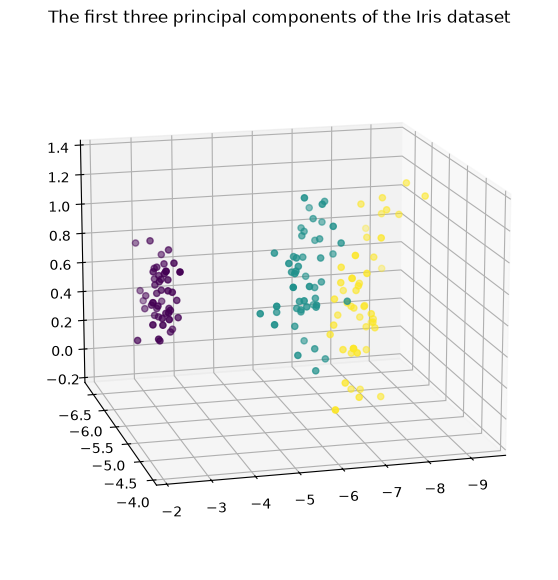

In [5]:
iris = datasets.load_iris()
x = iris.data
C = np.cov(x, rowvar=False)
print(C)
T, s, Tinv = np.linalg.svd(C)
pca_x = np.matmul(Tinv, x.T).T

fig, ax = plt.subplots()
ax.scatter(pca_x[:,0], pca_x[:,1], c=iris.target, alpha=0.6)
ax.set_title("The first two principal components of the Iris dataset")
plt.show()

fig = plt.figure(figsize=(7,7))
ax = plt.axes(projection='3d')
ax.view_init(15, 75)
ax.scatter3D(pca_x[:,0], pca_x[:,1], pca_x[:,2], c=iris.target)
ax.set_title("The first three principal components of the Iris dataset")
plt.show()

### Computation with Scikit-learn

We do not even have to compute the singular value decomposition or the eigenvectors of the covariance matrix ourselves – Scikit-learn can do that for us too:

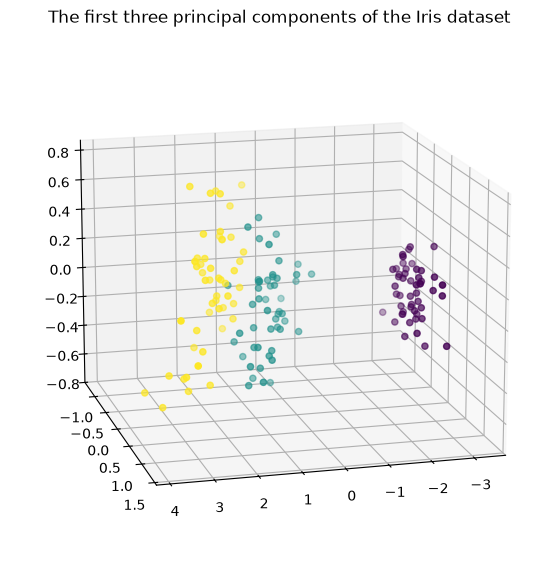

In [6]:
from sklearn.decomposition import PCA

pca_iris = PCA().fit_transform(iris.data)

fig = plt.figure(figsize=(7,7))
ax = plt.axes(projection='3d')
ax.view_init(15, 75)
ax.scatter3D(pca_iris[:,0], pca_iris[:,1], pca_iris[:,2], c=iris.target)
ax.set_title("The first three principal components of the Iris dataset")
plt.show()

A completely different approach to finding the direction of maximal variance is to minimise the sum of the squared distances of the points from a straight line.

Up to the factor $\frac1n$, the sum of the squared distances is a mean squared error. And for the $\texttt{mse}$ we already know the best constant model: it is the mean (chapter [Expected value and variance](expectation-variance.md), section "Squared deviation"). In this sense the first principal component is the best *linear* model – the straight line through the mean that minimises the mean squared distance – and the animation shows that this is exactly the direction of greatest variance.

One easily missed detail distinguishes PCA from [linear regression](linear-regression.ipynb): here it is the *perpendicular* distance to the line that is minimised, whereas in regression it is the vertical distance, in the direction of the target variable. The two lines are therefore in general different.

Here is a picture of how this works:

```{figure} images/pca-variation.gif
:width: 600px
:align: center
:name: pca-variation

The line rotates until the sum of the squared distances is minimal – and that is the direction of greatest variance.
```

### Application example: MNIST

So far we have reduced the dimension only for plotting – but many algorithms need the dimension kept at least small enough that the program does not run for weeks. A dataset with rather more than $4$ variables is the MNIST dataset of handwritten digits.

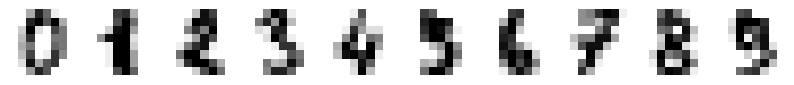

0.7250791394789893
0.7437984495348842
0.8572992273791208


In [7]:
digits = datasets.load_digits()
fig, axs = plt.subplots(1,10, figsize=(10,1))
for i in range(10):
    axs[i].axis("off")
    axs[i].matshow(digits.images[i],
                   cmap='gray_r')
plt.show()
x = digits.data
pca_x = PCA().fit_transform(x)

from sklearn.cluster import KMeans
kmeans_result = KMeans(n_clusters=10, n_init=1).fit(x)
kmeans_after_pca = KMeans(n_clusters=10, n_init=1).fit(pca_x)

from sklearn import metrics
print(metrics.normalized_mutual_info_score(digits.target, kmeans_result.labels_))
print(metrics.normalized_mutual_info_score(digits.target, kmeans_after_pca.labels_))
print(metrics.normalized_mutual_info_score(kmeans_result.labels_, kmeans_after_pca.labels_))

How many components do you need? Scikit-learn gives the explained variance of every component directly (`explained_variance_ratio_`: the eigenvalues of the covariance matrix divided by their sum). The cumulative curve shows how much variance the first $n$ components explain together:

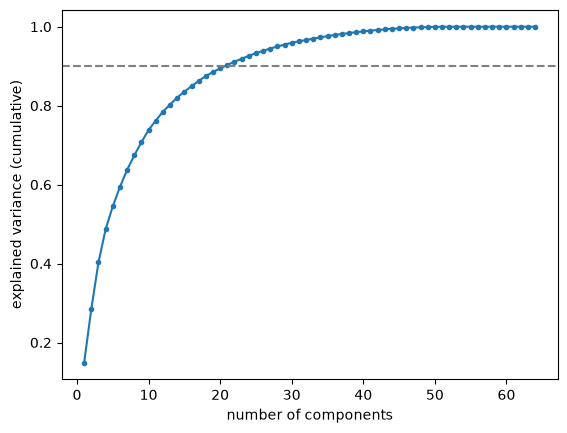

components for 90% of the variance: 21 out of 64


In [8]:
pca = PCA().fit(x)
ratio = pca.explained_variance_ratio_
cumulative = np.cumsum(ratio)

fig, ax = plt.subplots()
ax.plot(np.arange(1, len(ratio) + 1), cumulative, marker=".")
ax.axhline(0.9, linestyle="--", color="gray")
ax.set_xlabel("number of components")
ax.set_ylabel("explained variance (cumulative)")
plt.show()
print("components for 90% of the variance:", np.searchsorted(cumulative, 0.9) + 1, "out of", len(ratio))

In [9]:
# Now we throw dimensions away
# and analyse how the classification suffers as a result:
scores = np.full(33, 0.0)
pca_x = PCA().fit_transform(x)

def update_scores(scores, pca_x, maxn, minn):
    for n in range(maxn, minn-1, -1):
        pca_x = pca_x[:,:n]
        kmeans_after_pca = KMeans(n_clusters=10, n_init=1).fit(pca_x)
        scores[n] = metrics.normalized_mutual_info_score(digits.target, kmeans_after_pca.labels_)
    return scores, pca_x

In [10]:
# Work in batches to avoid Jupyter cell timeout after 30 seconds:
scores, pca_x = update_scores(scores, pca_x, 32, 17)

In [11]:
scores, pca_x = update_scores(scores, pca_x, 16, 1)

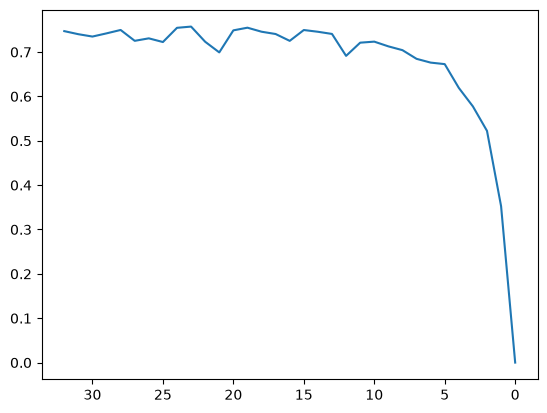

In [12]:
fig, ax = plt.subplots()
ax.plot(np.arange(0, 33), scores)
ax.invert_xaxis()
plt.show()

As the graph shows, the performance of 10-means as a classifier only suffers once we are down from the original 64 dimensions to no more than 10 and keep reducing.

In the Iris data we have already seen that the covariance matrices within the groups come out slightly different. Strictly speaking, for an optimal separation of the groups we do not want to favour the directions of greatest variance at all; we would much rather have the direction that separates best. To look at that, however, you have to know the classes already – which makes it supervised learning. One such method is linear discriminant analysis (LDA).

## Differences in scale

Things become problematic when the data do not all lie on the same scale, as they did in the examples so far (metres in one place, centimetres in another), or when the scales are even unknown or incompatible (seconds, metres).

Then the variables with large numbers dominate, which is a distortion of the coordinate transformation we were actually after. To avoid this, you rescale every variable by its standard deviation, and likewise shift every variable so that its mean becomes $0$. This is called 'standardisation'. It is particularly sensible when the variable is approximately normally distributed.

A 'normalisation' is a rescaling onto the interval $[0,1]$. It is particularly sensible when the variable is not normally distributed.

Any such rescaling is called 'feature scaling'.

In Python, Scikit-Learn does this with a `Scaler` object:

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

np.random.seed(1234)

# craft some dummy data:
dummycenters = [[10, 0.04, 3],
                [20, 0.03, 2],
                [30, 0.02, 1],
                [40, 0.01, 4]]
# make a random symmetric matrix with A@A.T for a random matrix A,
# make it positive definite by adding an identity matrix
dummycovs = (4*(A@A.T + np.eye(3))
             for A in (np.random.rand(3,3)
                       for _ in range(4)))
dummydata = np.concatenate([np.random.multivariate_normal(center,
                                                          cov,
                                                          size=200)
             for center, cov in zip(dummycenters, dummycovs)])
dummymu = np.mean(dummydata, axis=0)

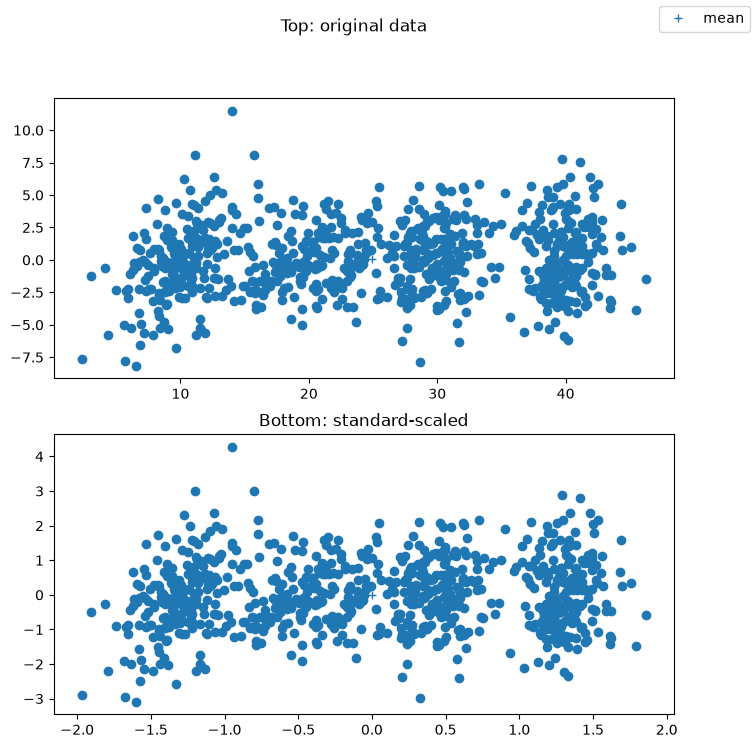

In [14]:
# scale it:
scaler = StandardScaler()
scaled = scaler.fit_transform(dummydata)
scaledmu = np.mean(scaled, axis=0)

# let's take a look:
fig, axs = plt.subplots(2, 1, figsize=(8,8))
axs[0].scatter(dummydata[:,0], dummydata[:,1])
axs[0].plot(dummymu[0], dummymu[1], "+",
            label="mean")
axs[1].scatter(scaled[:,0], scaled[:,1])
axs[1].plot(scaledmu[0], scaledmu[1], "+")
axs[1].set_title("Bottom: standard-scaled")
fig.legend()
fig.suptitle("Top: original data")
plt.show()

We now look at how scaling affects PCA and the k-means clustering that follows it,
because instead of simply putting everything through the StandardScaler every time, you should always look at what difference it makes:

In [15]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

dummy_pca = PCA().fit_transform(dummydata)
scaled_pca = PCA().fit_transform(scaled)

dummy_kmeans = KMeans(4, n_init=1).fit(dummy_pca)
scaled_kmeans = KMeans(4, n_init=1).fit(scaled_pca)

# to compare:
original_labels = np.concatenate([np.full(200, k) for k in range(4)])

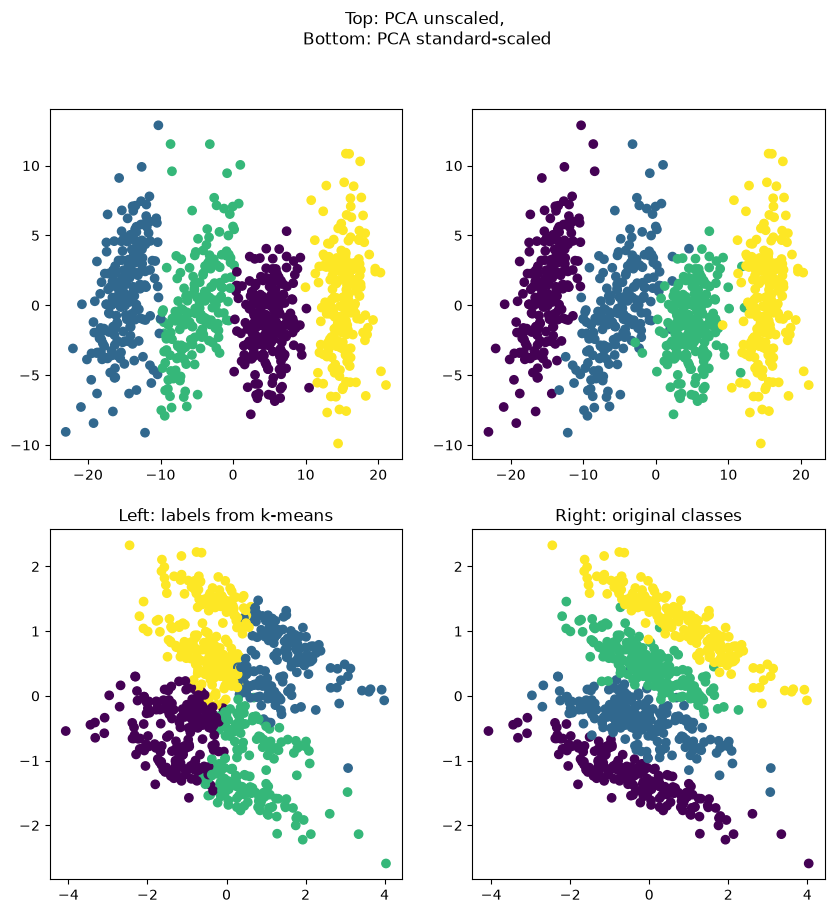

In [16]:
# let's take a look:
fig, axs = plt.subplots(2, 2, figsize=(10,10))
axs[0][0].scatter(dummy_pca[:,0], dummy_pca[:,1],
               c=dummy_kmeans.labels_)
axs[1][0].scatter(scaled_pca[:,0], scaled_pca[:,1],
               c=scaled_kmeans.labels_)
axs[0][1].scatter(dummy_pca[:,0], dummy_pca[:,1],
               c=original_labels)
axs[1][1].scatter(scaled_pca[:,0], scaled_pca[:,1],
               c=original_labels)
axs[1][0].set_title("Left: labels from k-means")
axs[1][1].set_title("Right: original classes")
fig.suptitle("Top: PCA unscaled,\n Bottom: PCA standard-scaled")
plt.show()

The top row clearly shows that k-means works well on the unscaled data.
The bottom row shows that with standard scaling the principal components lie differently (which is why the picture looks rotated),
but also that k-means has not divided the clusters up well.

This is ultimately an incarnation of Simpson's paradox: the "right" way to scale the data here would make the clusters as close to standard normally distributed as possible. To achieve that, however, you would first have to cluster, then compute the standard scaling of the clusters, and then scale all the data together by a suitable mean of those. Clustering after that yields a different picture again – and the procedure can be iterated. In this setting it pays not to use k-means at all, but to go straight to a method that does not assume standard normally distributed clusters (Gaussian mixture models, for example).

### Application example: Wine

Finally we look at a 'success story' for standard scaling:

In [17]:
import pandas as pd
from sklearn.datasets import load_wine

df, target = load_wine(return_X_y=True, as_frame=True)
assert type(df) == pd.DataFrame
assert type(target) == pd.Series

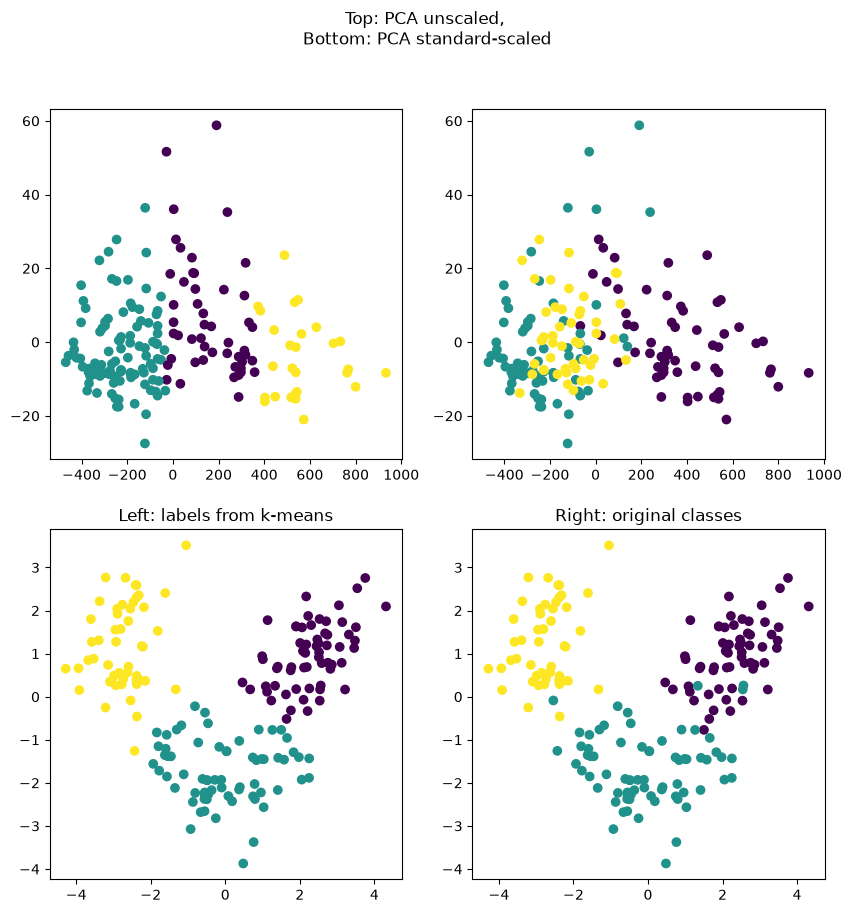

In [18]:
unscaled_pca = PCA(n_components=2).fit_transform(df)
unscaled_kmeans = KMeans(3, n_init=1).fit(unscaled_pca)

scaled = StandardScaler().fit_transform(df)
scaled_pca = PCA(n_components=2).fit_transform(scaled)
scaled_kmeans = KMeans(3, n_init=1).fit(scaled_pca)

fig, axs = plt.subplots(2, 2, figsize=(10,10))
axs[0][0].scatter(unscaled_pca[:,0], unscaled_pca[:,1], c=unscaled_kmeans.labels_)
axs[1][0].scatter(scaled_pca[:,0], scaled_pca[:,1], c=scaled_kmeans.labels_)
axs[0][1].scatter(unscaled_pca[:,0], unscaled_pca[:,1], c=target)
axs[1][1].scatter(scaled_pca[:,0], scaled_pca[:,1], c=target)
axs[1][0].set_title("Left: labels from k-means")
axs[1][1].set_title("Right: original classes")
fig.suptitle("Top: PCA unscaled,\n Bottom: PCA standard-scaled")
plt.show()

Rather than going by the picture alone, it is better to compute a summary measure as well. As before, we use an entropy-based measure: the *mutual information* $I(X;Y)$ of the two class variables (chapter [Relative entropy](relative-entropy.md)), normalised by the mean of their two entropies:

In [19]:
from sklearn.metrics import normalized_mutual_info_score

scaled_score = normalized_mutual_info_score(scaled_kmeans.labels_, target)
unscaled_score = normalized_mutual_info_score(unscaled_kmeans.labels_, target)

print("The scaled version, with a similarity of %f to the 'true' class, is better than the unscaled version with a similarity of only %f" % (scaled_score, unscaled_score))

The scaled version, with a similarity of 0.865642 to the 'true' class, is better than the unscaled version with a similarity of only 0.423309
